In [5]:
#snowalbedo的相关性计算.
import pandas as pd
import numpy as np

# 1️⃣ 读取 CSV
file_path = r"F:\TUB\greenlandProject\ERA5LAND\snowalbedo\all_stations_snowbilinear.csv"
df = pd.read_csv(file_path, dtype=str)

# 2️⃣ 转换为 float，并忽略无效值
df['fal'] = pd.to_numeric(df['fal'], errors='coerce')
df['interp_fal'] = pd.to_numeric(df['interp_fal'], errors='coerce')

# 3️⃣ 丢弃空值（NaN）
df = df.dropna(subset=['asn', 'interp_asn'])

# 如果丢弃后没有数据，就直接提示
if len(df) == 0:
    print("没有有效的 asn 和 interp_asn 数据，无法计算统计指标。")
else:
    # 4️⃣ 计算 Pearson 相关系数
    # 方式 A: 用 pandas 自带 corr() 计算
    pearson_r = df['asn'].corr(df['interp_asn'], method='pearson')

    # 5️⃣ 计算均方根误差 (RMSE)
    #   RMSE = sqrt(平均((asn - interp_asn)^2))
    rmse = np.sqrt(np.mean((df['asn'] - df['interp_asn'])**2))

    # 6️⃣ 计算平均偏差 (Bias)
    #   Bias = 平均( asn - interp_asn )
    bias = np.mean(df['asn'] - df['interp_asn'])

    # 7️⃣ 输出结果
    print(f"Pearson 相关系数 (r)  : {pearson_r:.4f}")
    print(f"均方根误差 (RMSE)   : {rmse:.4f}")
    print(f"平均偏差 (Bias)     : {bias:.4f}")


Pearson 相关系数 (r)  : 0.3458
均方根误差 (RMSE)   : 0.2084
平均偏差 (Bias)     : -0.1131


E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25554 (\N{CJK UNIFIED IDEOGRAPH-63D2}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25955 (\N{CJK UNIFIED IDEOGRAPH-6563}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabt

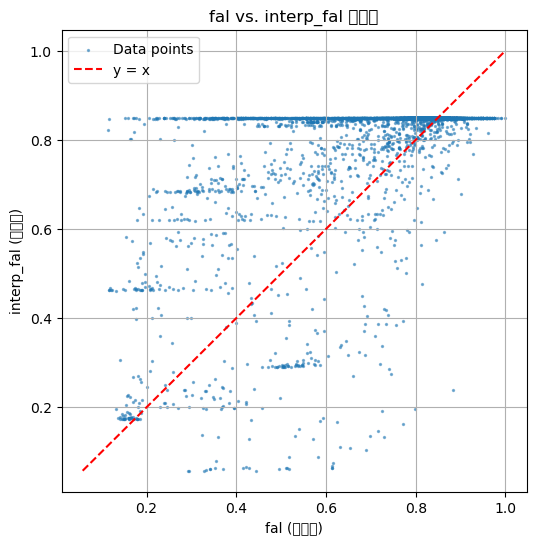

Pearson 相关系数 (r)  : 0.5624
均方根误差 (RMSE)   : 0.1765
平均偏差 (Bias)     : -0.0755


In [52]:
#forecast-albedo的相关性计算.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1️⃣ 读取 CSV
file_path = r"F:\TUB\greenlandProject\ERA5LAND\forecastalbedo\all_stations_bilinear.csv"
df = pd.read_csv(file_path, dtype=str)

# 2️⃣ 转换为 float，并忽略无效值
df['fal'] = pd.to_numeric(df['fal'], errors='coerce')
df['interp_fal'] = pd.to_numeric(df['interp_fal'], errors='coerce')

# 3️⃣ 丢弃空值（NaN）
df = df.dropna(subset=['fal', 'interp_fal'])

# 如果丢弃后没有数据，就直接提示
if len(df) == 0:
    print("没有有效的 fal 和 interp_fal 数据，无法计算统计指标。")
else:
    # 4️⃣ 计算 Pearson 相关系数
    # 方式 A: 用 pandas 自带 corr() 计算
    pearson_r = df['fal'].corr(df['interp_fal'], method='pearson')

    # 5️⃣ 计算均方根误差 (RMSE)
    #   RMSE = sqrt(平均((fal - interp_fal)^2))
    rmse = np.sqrt(np.mean((df['fal'] - df['interp_fal'])**2))

    # 6️⃣ 计算平均偏差 (Bias)
    #   Bias = 平均( fal - interp_fal )
    bias = np.mean(df['fal'] - df['interp_fal'])
     # 3️⃣ 画散点图
    plt.figure(figsize=(6, 6))
    plt.scatter(df['fal'], df['interp_fal'], s=2, alpha=0.5, label='Data points')  # 调小点的大小 s=5

    
    # 4️⃣ 画 y = x 参考线（用于比较两者大小差异）
    min_val = min(df['fal'].min(), df['interp_fal'].min())
    max_val = max(df['fal'].max(), df['interp_fal'].max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='y = x')
    
    # 5️⃣ 设置标题和坐标轴
    plt.xlabel('fal (观测值)')
    plt.ylabel('interp_fal (插值值)')
    plt.title('fal vs. interp_fal 散点图')
    plt.legend()
    plt.grid(True)
    
    # 6️⃣ 显示图像
    plt.show()

    # 7️⃣ 输出结果
    print(f"Pearson 相关系数 (r)  : {pearson_r:.4f}")
    print(f"均方根误差 (RMSE)   : {rmse:.4f}")
    print(f"平均偏差 (Bias)     : {bias:.4f}")

In [4]:
import pandas as pd

file_path = r"F:\TUB\greenlandProject\ERA5LAND\snowalbedo\all_stations_snowbilinear.csv"


# 读取 CSV 文件
df = pd.read_csv(file_path, sep=None, engine="python")

# 预处理列名（去除空格）
df.columns = df.columns.str.strip()

# 检查关键列是否存在
if "station" not in df.columns or "dif>0.2" not in df.columns:
    print("❌ Error: 'station' or 'dif>0.2' column not found in CSV file.")
    exit()

# 将 'dif>0.2' 列中的 'FALSE' 转换为 0，'1' 保持不变
df["dif>0.2"] = df["dif>0.2"].apply(lambda x: 1 if str(x) == '1' else 0)

# 统计每个 station 的 1 的占比
result = {}
for station, group in df.groupby("station"):
    total_count = len(group)  # 站点总记录数
    count_ones = group["dif>0.2"].sum()  # 'dif>0.2' 为 1 的数量
    ratio = count_ones / total_count  # 计算占比

    if ratio > 0.2:  # 如果占比大于 20%
        result[station] = ratio

# 输出符合条件的 station 及其 1 的占比
print("\n📊 **符合条件的站点统计**")
if result:
    for station, ratio in result.items():
        print(f"🔹 Station: {station}, Ratio of 1s: {ratio:.2%}")
else:
    print("🚫 没有符合条件的站点。")



📊 **符合条件的站点统计**
🔹 Station: FRE, Ratio of 1s: 41.18%
🔹 Station: JAR, Ratio of 1s: 35.40%
🔹 Station: KAN_B, Ratio of 1s: 82.47%
🔹 Station: KAN_L, Ratio of 1s: 29.20%
🔹 Station: KAN_M, Ratio of 1s: 29.09%
🔹 Station: KAN_T, Ratio of 1s: 60.00%
🔹 Station: KPC_L, Ratio of 1s: 50.85%
🔹 Station: LYN_L, Ratio of 1s: 21.05%
🔹 Station: LYN_T, Ratio of 1s: 28.57%
🔹 Station: MIT, Ratio of 1s: 55.66%
🔹 Station: NUK_K, Ratio of 1s: 34.33%
🔹 Station: NUK_L, Ratio of 1s: 48.33%
🔹 Station: NUK_N, Ratio of 1s: 40.74%
🔹 Station: NUK_U, Ratio of 1s: 29.57%
🔹 Station: QAS_A, Ratio of 1s: 33.33%
🔹 Station: QAS_L, Ratio of 1s: 58.90%
🔹 Station: QAS_M, Ratio of 1s: 47.14%
🔹 Station: QAS_U, Ratio of 1s: 39.32%
🔹 Station: SCO_L, Ratio of 1s: 67.89%
🔹 Station: SCO_U, Ratio of 1s: 55.24%
🔹 Station: SWC, Ratio of 1s: 22.63%
🔹 Station: TAS_A, Ratio of 1s: 28.36%
🔹 Station: TAS_L, Ratio of 1s: 59.05%
🔹 Station: TAS_U, Ratio of 1s: 50.00%
🔹 Station: THU_L, Ratio of 1s: 38.16%
🔹 Station: THU_L2, Ratio of 1s: 35.29%
🔹 

In [53]:
import pandas as pd
import numpy as np

# 1️⃣ 读取 Excel 文件
file_path = r"F:\TUB\greenlandProject\BIGdif_foreANDsnow.xlsx"
df = pd.read_excel(file_path)

# 2️⃣ 转换相关列为数值类型，并忽略无效值
df['interp_asn'] = pd.to_numeric(df['interp_asn'], errors='coerce')
df['interp_fal'] = pd.to_numeric(df['interp_fal'], errors='coerce')

# 3️⃣ 丢弃 NaN 值
df = df.dropna(subset=['interp_asn', 'interp_fal'])

# 4️⃣ 计算 Pearson 相关系数
pearson_r = df['interp_asn'].corr(df['interp_fal'], method='pearson')

# 5️⃣ 计算均方根误差 (RMSE)
rmse = np.sqrt(np.mean((df['interp_asn'] - df['interp_fal'])**2))

# 6️⃣ 计算平均偏差 (Bias)
bias = np.mean(df['interp_asn'] - df['interp_fal'])

# 7️⃣ 输出结果
print(f"Pearson 相关系数 (r)  : {pearson_r:.4f}")
print(f"均方根误差 (RMSE)   : {rmse:.4f}")
print(f"平均偏差 (Bias)     : {bias:.4f}")


Pearson 相关系数 (r)  : 0.6498
均方根误差 (RMSE)   : 0.1282
平均偏差 (Bias)     : 0.0376
